# 08 · Comparación de los 4 modelos y selección del modelo óptimo

Corresponde a las **secciones 9 (Comparación de algoritmos) y 10 (Selección del modelo óptimo)** del protocolo.

Todas las cifras se leen de los archivos `resultados/<modelo>/metricas.json` y `predicciones_prueba.csv` que generaron los
notebooks 04-07 (ninguna se escribe a mano). Los cuatro modelos usaron **la misma partición**, **el mismo preprocesamiento**,
**el mismo TF-IDF** y **la misma validación cruzada**, así que la comparación es justa.

Criterios de selección del protocolo: **mayor F1**, **mejor capacidad de generalización**, **menos errores de clasificación**,
**estabilidad de resultados**, equilibrando con el **costo computacional**.

In [1]:
import json
import shutil
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score, recall_score

import utils
from utils import CLASES, SEMILLA, RESULTADOS, MODELOS

SALIDA = RESULTADOS / "comparacion"
SALIDA.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

def a_markdown(tabla, decimales=4):
    # Convierte un DataFrame en tabla Markdown (sin dependencias extra)
    t = tabla.copy()
    for c in t.columns:
        if pd.api.types.is_float_dtype(t[c]):
            t[c] = t[c].map(lambda v: f"{v:.{decimales}f}")
    encabezado = "| " + " | ".join([t.index.name or ""] + list(map(str, t.columns))) + " |"
    separador = "|" + "---|" * (len(t.columns) + 1)
    filas = ["| " + " | ".join([str(i)] + [str(v) for v in fila]) + " |" for i, fila in zip(t.index, t.values)]
    return "\n".join([encabezado, separador] + filas)

## 1. Tabla comparativa

In [2]:
crudo = pd.DataFrame([json.load(open(RESULTADOS / clave / "metricas.json", encoding="utf-8"))
                      for clave in utils.MODELOS_PROYECTO.values()]).set_index("modelo")

tabla = pd.DataFrame({
    "Accuracy": crudo["accuracy"],
    "Precision (macro)": crudo["precision_macro"],
    "Recall (macro)": crudo["recall_macro"],
    "F1 (macro)": crudo["f1_macro"],
    "F1 (ponderado)": crudo["f1_ponderado"],
    "F1 Envío": crudo["f1_Envío"],
    "F1 Producto": crudo["f1_Producto"],
    "F1 Sentimiento": crudo["f1_Sentimiento"],
    "F1 macro CV (media)": crudo["cv_f1_macro_media"],
    "F1 macro CV (desv. est.)": crudo["cv_f1_macro_std"],
    "Brecha CV - prueba": crudo["cv_f1_macro_media"] - crudo["f1_macro"],
    "Errores en prueba": crudo["n_errores"].astype(int),
    "Tiempo búsqueda (s)": crudo["tiempo_busqueda_s"],
    "Tiempo entrenamiento (s)": crudo["tiempo_entrenamiento_s"],
    "Tiempo predicción (s)": crudo["tiempo_prediccion_s"],
})
tabla.index.name = "Modelo"
tabla.to_csv(SALIDA / "tabla_comparativa.csv", encoding="utf-8-sig")

texto_md = ("# Tabla comparativa de modelos (conjunto de prueba, n = "
            f"{int(crudo['n_prueba'].iloc[0])} reseñas)\n\n" + a_markdown(tabla) +
            "\n\nMétricas de prueba con etiquetas generadas por reglas. CV = validación cruzada estratificada de 5 pliegues "
            "sobre entrenamiento. Brecha = F1 macro CV − F1 macro prueba. Tiempos medidos con time.perf_counter().\n")
(SALIDA / "tabla_comparativa.md").write_text(texto_md, encoding="utf-8")

print("Mejores hiperparámetros por modelo:")
for modelo, hp in crudo["mejores_hiperparametros"].items():
    print(f"  {modelo}: {hp}")
tabla.round(4)

Mejores hiperparámetros por modelo:
  KNN: {'clf__n_neighbors': '5', 'clf__weights': 'uniform'}
  Naive Bayes: {'clf__alpha': '0.1'}
  SVM: {'clf': "LinearSVC(class_weight='balanced', max_iter=20000, random_state=42)", 'clf__C': '0.3'}
  Random Forest: {'clf__max_depth': 'None', 'clf__min_samples_leaf': '2', 'clf__n_estimators': '200'}


,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (ponderado),F1 Envío,F1 Producto,F1 Sentimiento,F1 macro CV (media),F1 macro CV (desv. est.),Brecha CV - prueba,Errores en prueba,Tiempo búsqueda (s),Tiempo entrenamiento (s),Tiempo predicción (s)
Modelo,,,,,,,,,,,,,,,
KNN,0.7063,0.6598,0.5264,0.5586,0.6912,0.3191,0.5723,0.7845,0.5720,0.0270,0.0134,871,44.8065,1.1738,0.7097
Naive Bayes,0.7202,0.5940,0.6123,0.5955,0.7237,0.3310,0.7024,0.7532,0.6248,0.0094,0.0292,830,17.6693,2.1131,0.1955
SVM,0.8240,0.7681,0.6955,0.7241,0.8225,0.5310,0.7782,0.8631,0.7115,0.0126,-0.0126,522,192.9144,2.3042,0.1992
Random Forest,0.7839,0.6762,0.6860,0.6807,0.7852,0.4748,0.7399,0.8272,0.6973,0.0234,0.0166,641,227.8205,15.7856,0.7972


## 2. Gráficas comparativas

### 2.1 Métricas principales (macro) y F1 por clase

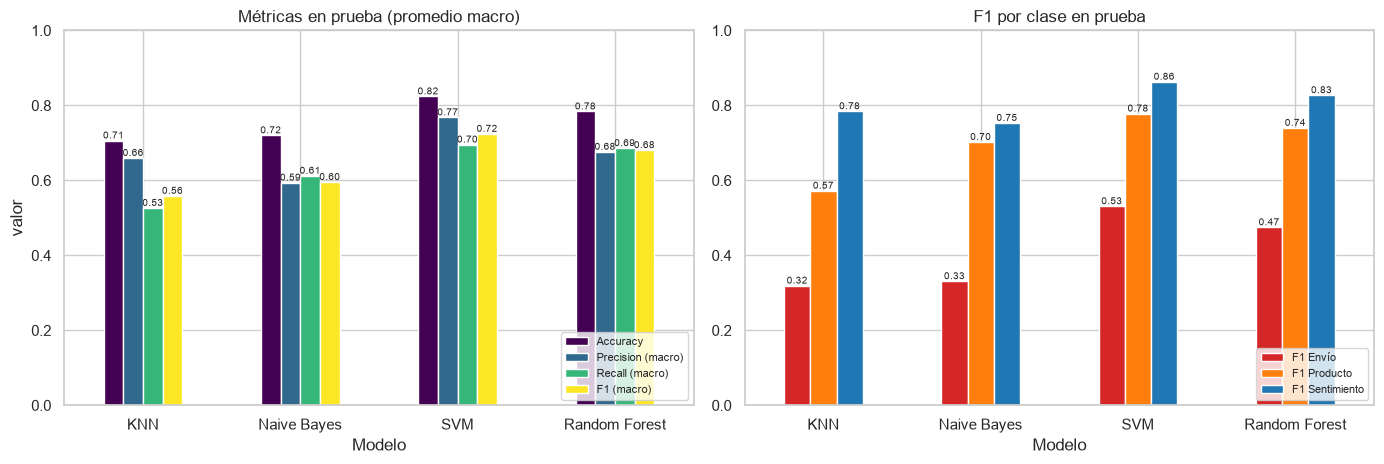

In [3]:
principales = tabla[["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)"]]
por_clase = tabla[["F1 Envío", "F1 Producto", "F1 Sentimiento"]]

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.8))
principales.plot(kind="bar", ax=ejes[0], rot=0, colormap="viridis")
ejes[0].set_title("Métricas en prueba (promedio macro)"); ejes[0].set_ylim(0, 1); ejes[0].set_ylabel("valor")
ejes[0].legend(loc="lower right", fontsize=8)
for contenedor in ejes[0].containers:
    ejes[0].bar_label(contenedor, fmt="%.2f", fontsize=7)
por_clase.plot(kind="bar", ax=ejes[1], rot=0, color=["tab:red", "tab:orange", "tab:blue"])
ejes[1].set_title("F1 por clase en prueba"); ejes[1].set_ylim(0, 1)
ejes[1].legend(loc="lower right", fontsize=8)
for contenedor in ejes[1].containers:
    ejes[1].bar_label(contenedor, fmt="%.2f", fontsize=7)
fig.tight_layout(); fig.savefig(SALIDA / "metricas_comparadas.png", dpi=120); plt.show()

### 2.2 Generalización y estabilidad: F1 macro en validación cruzada vs. prueba

Las barras de error son la desviación estándar entre los 5 pliegues. Si el F1 de prueba queda dentro del rango de la validación
cruzada, el modelo **generaliza** bien; una desviación pequeña indica **estabilidad**.

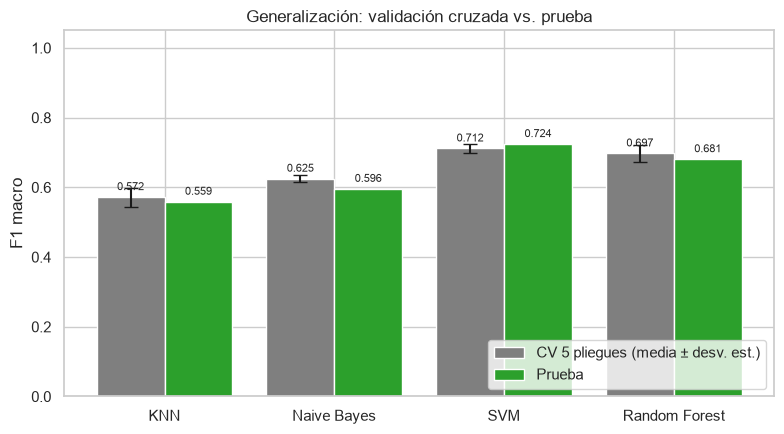

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(tabla))
ax.bar(x - 0.2, tabla["F1 macro CV (media)"], 0.4, yerr=tabla["F1 macro CV (desv. est.)"], capsize=5,
       label="CV 5 pliegues (media ± desv. est.)", color="tab:gray")
ax.bar(x + 0.2, tabla["F1 (macro)"], 0.4, label="Prueba", color="tab:green")
for i, (cv_, te) in enumerate(zip(tabla["F1 macro CV (media)"], tabla["F1 (macro)"])):
    ax.text(i - 0.2, cv_ + 0.02, f"{cv_:.3f}", ha="center", fontsize=8)
    ax.text(i + 0.2, te + 0.02, f"{te:.3f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(tabla.index); ax.set_ylim(0, 1.05); ax.set_ylabel("F1 macro")
ax.set_title("Generalización: validación cruzada vs. prueba"); ax.legend(loc="lower right")
fig.tight_layout(); fig.savefig(SALIDA / "cv_vs_prueba.png", dpi=120); plt.show()

### 2.3 Costo computacional (escala logarítmica)

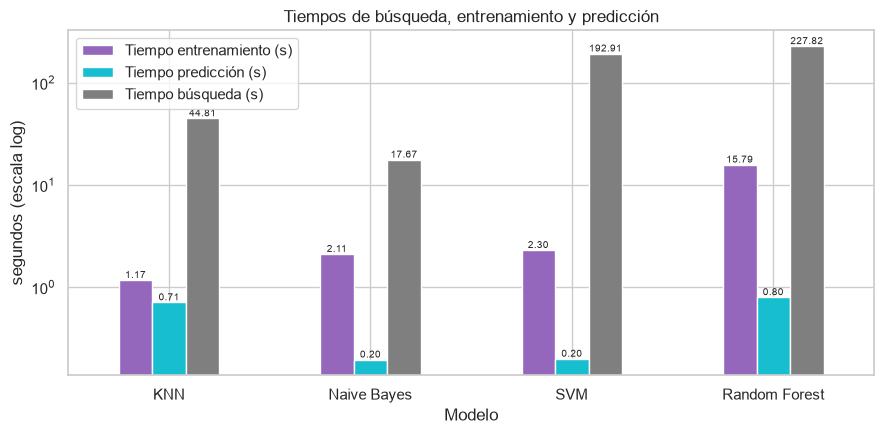

In [5]:
tiempos = tabla[["Tiempo entrenamiento (s)", "Tiempo predicción (s)", "Tiempo búsqueda (s)"]]
fig, ax = plt.subplots(figsize=(9, 4.5))
tiempos.plot(kind="bar", ax=ax, rot=0, logy=True, color=["tab:purple", "tab:cyan", "tab:gray"])
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.2f", fontsize=7)
ax.set_ylabel("segundos (escala log)"); ax.set_title("Tiempos de búsqueda, entrenamiento y predicción")
fig.tight_layout(); fig.savefig(SALIDA / "tiempos.png", dpi=120); plt.show()

**Referencia de costo del TF-IDF.** El tiempo de entrenamiento de cada pipeline incluye ajustar el TF-IDF (común a los
4 modelos) y el clasificador. Como referencia medimos cuánto tarda **solo** el TF-IDF con el mismo entrenamiento (mediana de 3).
Los tiempos de pocos segundos varían entre ejecuciones según la carga del equipo, así que diferencias de alrededor de un segundo
entre KNN, Naive Bayes y SVM no son significativas; la diferencia con Random Forest sí lo es.

In [6]:
import time
datos_entrenamiento = pd.read_csv(utils.ARCHIVO_PROCESADO, encoding="utf-8-sig", keep_default_na=False)
datos_entrenamiento = datos_entrenamiento[datos_entrenamiento["particion"] == "entrenamiento"]
mediciones = []
for _ in range(3):
    inicio = time.perf_counter()
    utils.crear_vectorizador().fit_transform(datos_entrenamiento["texto_procesado"])
    mediciones.append(time.perf_counter() - inicio)
t_tfidf = float(np.median(mediciones))
desglose = pd.DataFrame({"Tiempo entrenamiento del pipeline (s)": tabla["Tiempo entrenamiento (s)"]})
desglose["Solo TF-IDF, referencia (s)"] = t_tfidf
desglose.to_csv(SALIDA / "desglose_tiempo_entrenamiento.csv", encoding="utf-8-sig")
print(f"Ajuste del TF-IDF solo (mediana de 3): {t_tfidf:.2f} s  | mediciones: {[round(m, 2) for m in mediciones]}")
desglose.round(3)

Ajuste del TF-IDF solo (mediana de 3): 2.27 s  | mediciones: [2.27, 2.32, 1.75]


,Tiempo entrenamiento del pipeline (s),"Solo TF-IDF, referencia (s)"
Modelo,,
KNN,1.174,2.274
Naive Bayes,2.113,2.274
SVM,2.304,2.274
Random Forest,15.786,2.274


### 2.4 Matrices de confusión lado a lado

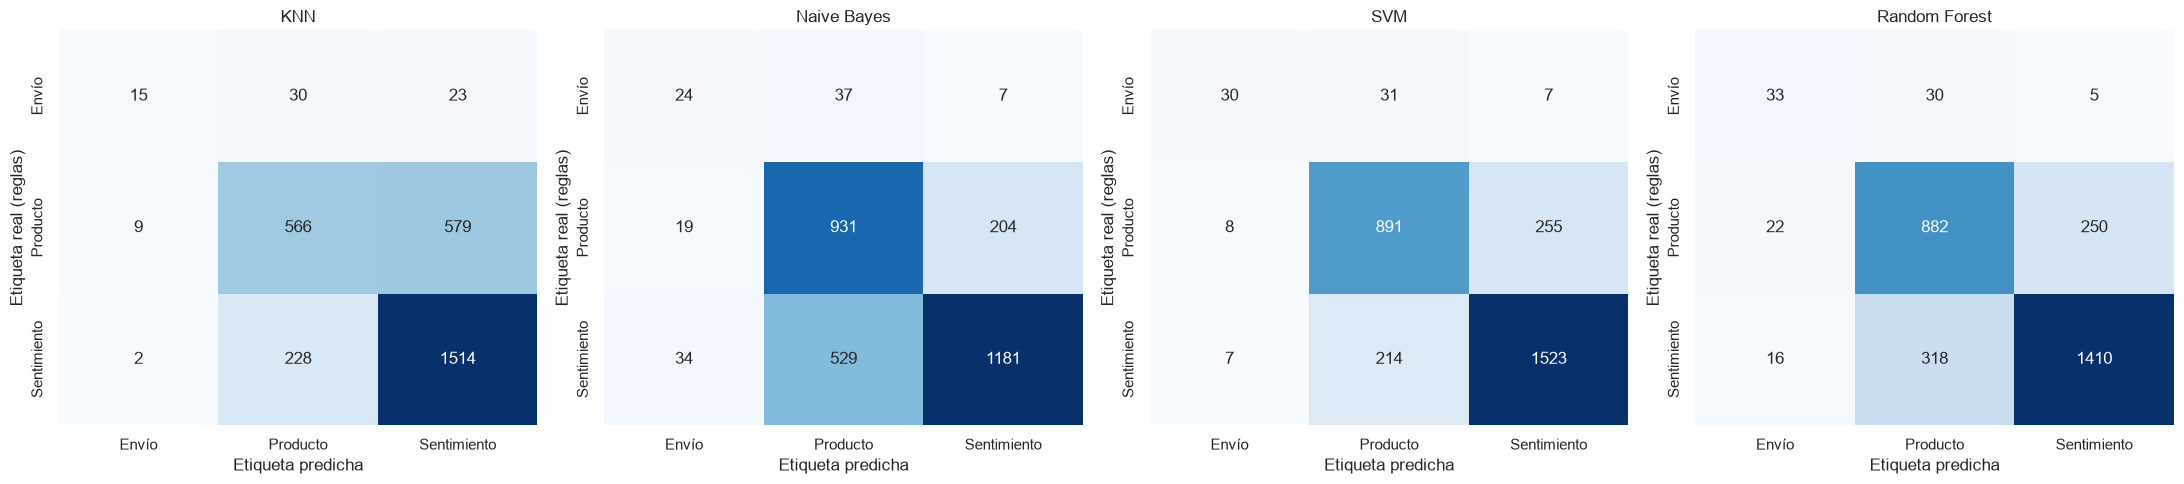

✔ Las métricas de la tabla coinciden con los CSV de predicciones.


In [7]:
predicciones = {nombre: pd.read_csv(RESULTADOS / clave / "predicciones_prueba.csv", encoding="utf-8-sig")
                for nombre, clave in utils.MODELOS_PROYECTO.items()}
fig, ejes = plt.subplots(1, 4, figsize=(22, 5))
for ax, (nombre, p) in zip(ejes, predicciones.items()):
    utils.graficar_matriz_confusion(p["etiqueta_real"], p["etiqueta_predicha"], nombre, SALIDA, ax=ax, guardar=False)
fig.tight_layout(); fig.savefig(SALIDA / "matrices_confusion.png", dpi=110); plt.show()

# Verificación: las métricas recalculadas desde los CSV de predicciones coinciden con metricas.json
for nombre, p in predicciones.items():
    f1_csv = f1_score(p["etiqueta_real"], p["etiqueta_predicha"], average="macro")
    assert abs(f1_csv - tabla.loc[nombre, "F1 (macro)"]) < 1e-9, nombre
print("✔ Las métricas de la tabla coinciden con los CSV de predicciones.")

### 2.5 Tipos de error más frecuentes y desempeño por polaridad (¿son más difíciles las de 3 estrellas?)

,,KNN,Naive Bayes,SVM,Random Forest,Total
etiqueta_real,etiqueta_predicha,,,,,
Sentimiento,Producto,228,529,214,318,1289
Producto,Sentimiento,579,204,255,250,1288
Envío,Producto,30,37,31,30,128
Sentimiento,Envío,2,34,7,16,59
Producto,Envío,9,19,8,22,58
Envío,Sentimiento,23,7,7,5,42


F1 macro por polaridad:


polaridad,negative,neutral,positive
modelo,,,
KNN,0.5386,0.5200,0.5203
Naive Bayes,0.5621,0.5067,0.5082
Random Forest,0.6935,0.5942,0.6359
SVM,0.7253,0.6646,0.7432


Accuracy por polaridad:


polaridad,negative,neutral,positive
modelo,,,
KNN,0.6325,0.6380,0.8483
Naive Bayes,0.6712,0.6507,0.8392
Random Forest,0.7592,0.7123,0.8817
SVM,0.8031,0.7661,0.9039


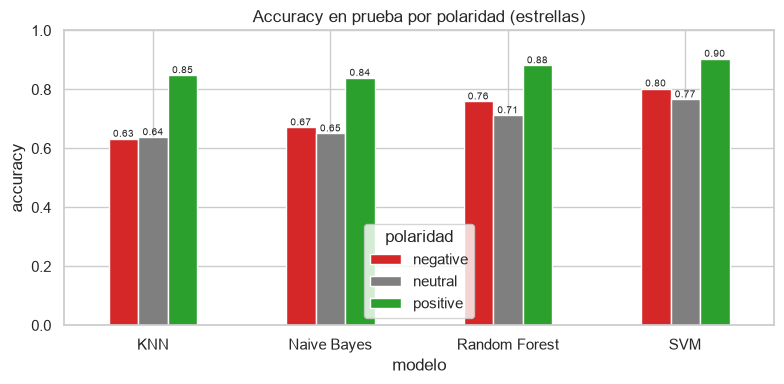

In [8]:
errores = []
for nombre, p in predicciones.items():
    e = p[~p["correcta"]].groupby(["etiqueta_real", "etiqueta_predicha"]).size().rename(nombre)
    errores.append(e)
errores = pd.concat(errores, axis=1).fillna(0).astype(int)
errores["Total"] = errores.sum(axis=1)
errores = errores.sort_values("Total", ascending=False)
errores.to_csv(SALIDA / "errores_por_tipo.csv", encoding="utf-8-sig")
display(errores)

polaridad = []
for nombre, clave in utils.MODELOS_PROYECTO.items():
    t = pd.read_csv(RESULTADOS / clave / "desempeno_por_polaridad.csv", encoding="utf-8-sig")
    t["modelo"] = nombre
    polaridad.append(t)
polaridad = pd.concat(polaridad)
pivote = polaridad.pivot(index="modelo", columns="polaridad", values="f1_macro")[["negative", "neutral", "positive"]]
pivote_acc = polaridad.pivot(index="modelo", columns="polaridad", values="accuracy")[["negative", "neutral", "positive"]]
pivote.to_csv(SALIDA / "f1_macro_por_polaridad.csv", encoding="utf-8-sig")
pivote_acc.to_csv(SALIDA / "accuracy_por_polaridad.csv", encoding="utf-8-sig")
print("F1 macro por polaridad:"); display(pivote.round(4))
print("Accuracy por polaridad:"); display(pivote_acc.round(4))

fig, ax = plt.subplots(figsize=(8, 4))
pivote_acc.plot(kind="bar", ax=ax, rot=0, color=["tab:red", "tab:gray", "tab:green"])
ax.set_ylim(0, 1); ax.set_ylabel("accuracy"); ax.set_title("Accuracy en prueba por polaridad (estrellas)")
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.2f", fontsize=7)
fig.tight_layout(); fig.savefig(SALIDA / "accuracy_por_polaridad.png", dpi=120); plt.show()

## 3. Selección del modelo óptimo

Regla de decisión (definida **antes** de ver qué modelo gana y aplicada en código):

1. **Criterio principal: mayor F1 macro en prueba** (trata a las tres clases por igual, incluida Envío, que es minoritaria).
2. Si otro modelo queda a menos de **0.005** de F1 macro del mejor (empate práctico), se prefiere el de **menor costo
   computacional** (tiempo de entrenamiento) y, después, el más **estable** (menor desviación en CV).
3. Además se reporta, para cada criterio del protocolo, la posición de cada modelo (1 = mejor):
   F1 macro, generalización (|brecha CV − prueba|), errores, estabilidad (desv. est. en CV) y tiempo de entrenamiento.

In [9]:
TOLERANCIA = 0.005
ranking = pd.DataFrame({
    "F1 macro": tabla["F1 (macro)"].rank(ascending=False, method="min"),
    "Generalización |brecha|": tabla["Brecha CV - prueba"].abs().rank(method="min"),
    "Errores": tabla["Errores en prueba"].rank(method="min"),
    "Estabilidad (desv. CV)": tabla["F1 macro CV (desv. est.)"].rank(method="min"),
    "Tiempo entrenamiento": tabla["Tiempo entrenamiento (s)"].rank(method="min"),
}).astype(int)
ranking["Suma de posiciones"] = ranking.sum(axis=1)
ranking.to_csv(SALIDA / "ranking_criterios.csv", encoding="utf-8-sig")
display(ranking)

mejor_f1 = tabla["F1 (macro)"].max()
candidatos = tabla[tabla["F1 (macro)"] >= mejor_f1 - TOLERANCIA]
elegido = candidatos.sort_values(["Tiempo entrenamiento (s)", "F1 macro CV (desv. est.)"]).index[0] \
    if len(candidatos) > 1 else candidatos.index[0]
e = tabla.loc[elegido]

print(f"Modelos dentro de {TOLERANCIA} del mejor F1 macro: {list(candidatos.index)}")
print(f"\n>>> MODELO ÓPTIMO: {elegido}\n")
print(f"- F1 macro en prueba: {e['F1 (macro)']:.4f} (posición {ranking.loc[elegido, 'F1 macro']} de 4); "
      f"accuracy {e['Accuracy']:.4f}; F1 de Envío {e['F1 Envío']:.4f}.")
print(f"- Generalización: F1 macro CV {e['F1 macro CV (media)']:.4f} vs. prueba {e['F1 (macro)']:.4f} "
      f"(brecha {e['Brecha CV - prueba']:+.4f}).")
print(f"- Estabilidad: desviación estándar entre pliegues {e['F1 macro CV (desv. est.)']:.4f}.")
print(f"- Errores en prueba: {int(e['Errores en prueba'])} de {int(crudo.loc[elegido, 'n_prueba'])}.")
print(f"- Costo: entrenamiento {e['Tiempo entrenamiento (s)']:.2f} s, predicción {e['Tiempo predicción (s)']:.3f} s.")
print("\nComparación con los demás:")
for otro in tabla.index.drop(elegido):
    o = tabla.loc[otro]
    print(f"  {otro:14s} F1 macro {o['F1 (macro)']:.4f} ({o['F1 (macro)'] - e['F1 (macro)']:+.4f}), "
          f"errores {int(o['Errores en prueba'])}, entrenamiento {o['Tiempo entrenamiento (s)']:.2f} s, "
          f"desv. CV {o['F1 macro CV (desv. est.)']:.4f}")

,F1 macro,Generalización |brecha|,Errores,Estabilidad (desv. CV),Tiempo entrenamiento,Suma de posiciones
Modelo,,,,,,
KNN,4,2,4,4,1,15
Naive Bayes,3,4,3,1,2,13
SVM,1,1,1,2,3,8
Random Forest,2,3,2,3,4,14


Modelos dentro de 0.005 del mejor F1 macro: ['SVM']

>>> MODELO ÓPTIMO: SVM

- F1 macro en prueba: 0.7241 (posición 1 de 4); accuracy 0.8240; F1 de Envío 0.5310.
- Generalización: F1 macro CV 0.7115 vs. prueba 0.7241 (brecha -0.0126).
- Estabilidad: desviación estándar entre pliegues 0.0126.
- Errores en prueba: 522 de 2966.
- Costo: entrenamiento 2.30 s, predicción 0.199 s.

Comparación con los demás:
  KNN            F1 macro 0.5586 (-0.1655), errores 871, entrenamiento 1.17 s, desv. CV 0.0270
  Naive Bayes    F1 macro 0.5955 (-0.1286), errores 830, entrenamiento 2.11 s, desv. CV 0.0094
  Random Forest  F1 macro 0.6807 (-0.0434), errores 641, entrenamiento 15.79 s, desv. CV 0.0234


In [10]:
# Guardar el modelo elegido como "mejor_modelo" para la función clasificar_resena()
clave = utils.MODELOS_PROYECTO[elegido]
shutil.copyfile(MODELOS / f"{clave}.joblib", MODELOS / "mejor_modelo.joblib")
info = {"modelo": elegido, "archivo_origen": f"modelos/{clave}.joblib",
        "regla_de_seleccion": f"mayor F1 macro en prueba; empate práctico (< {TOLERANCIA}) -> menor tiempo de entrenamiento",
        **{k: (float(v) if isinstance(v, (np.floating, float)) else int(v)) for k, v in e.items()},
        "mejores_hiperparametros": crudo.loc[elegido, "mejores_hiperparametros"]}
with open(MODELOS / "mejor_modelo_info.json", "w", encoding="utf-8") as f:
    json.dump(info, f, ensure_ascii=False, indent=2)
print("Guardado: modelos/mejor_modelo.joblib y modelos/mejor_modelo_info.json")

Guardado: modelos/mejor_modelo.joblib y modelos/mejor_modelo_info.json


## 4. Experimento complementario: entrenamiento balanceado por submuestreo

Para revisar si el desbalance (pocas reseñas de Envío) perjudica a los modelos, se reentrena cada modelo **con sus mismos
hiperparámetros** sobre un conjunto de entrenamiento **balanceado por submuestreo**: se toman al azar (semilla 42) tantas reseñas
de Producto y Sentimiento como reseñas de Envío hay. Se evalúa sobre **el mismo conjunto de prueba** (con su distribución real).

El submuestreo descarta muchos datos, así que normalmente mejora el *recall* de la clase minoritaria a costa de precisión en las otras.

In [11]:
entrenamiento = pd.read_csv(utils.ARCHIVO_PROCESADO, encoding="utf-8-sig", keep_default_na=False)
prueba = entrenamiento[entrenamiento["particion"] == "prueba"]
entrenamiento = entrenamiento[entrenamiento["particion"] == "entrenamiento"]
minoria = entrenamiento["etiqueta_reglas"].value_counts().min()
balanceado = entrenamiento.groupby("etiqueta_reglas").sample(n=minoria, random_state=SEMILLA)
print(f"Entrenamiento balanceado: {len(balanceado)} reseñas ({minoria} por clase)")

filas = []
for nombre, clave in utils.MODELOS_PROYECTO.items():
    modelo_b = clone(joblib.load(MODELOS / f"{clave}.joblib"))
    modelo_b.fit(balanceado["texto_procesado"], balanceado["etiqueta_reglas"])
    pred = modelo_b.predict(prueba["texto_procesado"])
    filas.append({
        "Modelo": nombre,
        "F1 macro (original)": tabla.loc[nombre, "F1 (macro)"],
        "F1 macro (submuestreo)": f1_score(prueba["etiqueta_reglas"], pred, average="macro"),
        "F1 Envío (original)": tabla.loc[nombre, "F1 Envío"],
        "F1 Envío (submuestreo)": f1_score(prueba["etiqueta_reglas"], pred, labels=["Envío"], average="macro"),
        "Recall Envío (original)": crudo.loc[nombre, "recall_Envío"],
        "Recall Envío (submuestreo)": recall_score(prueba["etiqueta_reglas"], pred, labels=["Envío"], average="macro"),
        "Accuracy (original)": tabla.loc[nombre, "Accuracy"],
        "Accuracy (submuestreo)": accuracy_score(prueba["etiqueta_reglas"], pred),
    })
submuestreo = pd.DataFrame(filas).set_index("Modelo")
submuestreo.to_csv(SALIDA / "experimento_submuestreo.csv", encoding="utf-8-sig")
(SALIDA / "experimento_submuestreo.md").write_text(a_markdown(submuestreo), encoding="utf-8")
submuestreo.round(4)

Entrenamiento balanceado: 822 reseñas (274 por clase)


,F1 macro (original),F1 macro (submuestreo),F1 Envío (original),F1 Envío (submuestreo),Recall Envío (original),Recall Envío (submuestreo),Accuracy (original),Accuracy (submuestreo)
Modelo,,,,,,,,
KNN,0.5586,0.4133,0.3191,0.1235,0.2206,0.6912,0.7063,0.5051
Naive Bayes,0.5955,0.4864,0.3310,0.2180,0.3529,0.7647,0.7202,0.5890
SVM,0.7241,0.5457,0.5310,0.2955,0.4412,0.8235,0.8240,0.6521
Random Forest,0.6807,0.5548,0.4748,0.3141,0.4853,0.8824,0.7839,0.6618


In [12]:
for nombre, fila in submuestreo.iterrows():
    cambio_f1 = fila["F1 macro (submuestreo)"] - fila["F1 macro (original)"]
    cambio_rec = fila["Recall Envío (submuestreo)"] - fila["Recall Envío (original)"]
    print(f"{nombre:14s} F1 macro {cambio_f1:+.4f} | recall de Envío {cambio_rec:+.4f}")
print("\nConclusión automática:",
      "el submuestreo mejora el F1 macro en al menos un modelo." if (submuestreo["F1 macro (submuestreo)"] > submuestreo["F1 macro (original)"]).any()
      else "el submuestreo NO mejora el F1 macro de ningún modelo; se conservan los modelos entrenados con todos los datos y pesos por clase.")

KNN            F1 macro -0.1453 | recall de Envío +0.4706
Naive Bayes    F1 macro -0.1092 | recall de Envío +0.4118
SVM            F1 macro -0.1784 | recall de Envío +0.3824
Random Forest  F1 macro -0.1259 | recall de Envío +0.3971

Conclusión automática: el submuestreo NO mejora el F1 macro de ningún modelo; se conservan los modelos entrenados con todos los datos y pesos por clase.


## 5. Función `clasificar_resena(texto)`

`utils.clasificar_resena` carga `modelos/mejor_modelo.joblib`, preprocesa el texto igual que en el entrenamiento y devuelve la
etiqueta, la confianza de la etiqueta elegida y los puntajes de las tres clases. Si el modelo no tiene probabilidades (SVM lineal),
la confianza es el *softmax* de la función de decisión: sirve para ordenar qué tan segura es la predicción, pero **no** es una probabilidad calibrada.

In [13]:
ejemplos = [
    "The package arrived two weeks late and the box was completely crushed.",
    "The handle snapped off after three uses and the pan started to rust.",
    "Absolutely love this blanket, so cozy and the color is beautiful!",
    "It's okay. Does the job, nothing special for the price.",
    "UPS left it at the wrong address and it arrived with a broken lid.",
]
filas = []
for texto in ejemplos:
    r = utils.clasificar_resena(texto)
    filas.append({"reseña": texto, "etiqueta": r["etiqueta"], "confianza": r["confianza"], **r["puntajes"]})
ejemplos_df = pd.DataFrame(filas)
ejemplos_df.to_csv(SALIDA / "ejemplos_clasificar_resena.csv", index=False, encoding="utf-8-sig")
print("Tipo de confianza:", utils.clasificar_resena(ejemplos[0])["tipo_confianza"])
ejemplos_df

Tipo de confianza: softmax de la función de decisión (no calibrada)


,reseña,etiqueta,confianza,Envío,Producto,Sentimiento
0,The package arrived two weeks late and the box was completely crushed.,Envío,0.8179,0.8179,0.0744,0.1077
1,The handle snapped off after three uses and the pan started to rust.,Producto,0.7066,0.1018,0.7066,0.1916
2,"Absolutely love this blanket, so cozy and the color is beautiful!",Sentimiento,0.8288,0.0648,0.1064,0.8288
3,"It's okay. Does the job, nothing special for the price.",Sentimiento,0.8075,0.0701,0.1224,0.8075
4,UPS left it at the wrong address and it arrived with a broken lid.,Envío,0.8986,0.8986,0.0248,0.0766
